# Логистическая регрессия и показатели ошибок классификации
![LogRegr.png](../asets/LogRegr.png)


# Цели обучения

- Описать логистическую регрессию и её отличия от линейной регрессии
- Определить метрики ошибок классификации и сценарии, в которых их можно использовать
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения



## Введение

Мы будем использовать базу данных [«Распознавание человеческой активности с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), которая была сформирована на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [1]:
from __future__ import print_function
import os
import time
import warnings
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, classification_report
from sklearn.preprocessing import label_binarize

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен, работает обычный scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

Импортируйте данные и выполните следующие действия:

* Проанализируйте типы данных — столбцов много, поэтому целесообразно использовать подсчёт значений
* Определите, требуется ли масштабирование значений с плавающей запятой
* Определите структуру каждого вида деятельности
* Кодируйте название вида деятельности в виде целого числа

In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)

(10299, 562)


Все столбцы данных содержат числа типа float, за исключением метки активности.

In [3]:
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

In [4]:
data.dtypes.tail()

angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
dtype: object

Все данные приведены к шкале от -1 (минимум) до 1,0 (максимум).

In [5]:
data.iloc[:, :-1].min().value_counts()

-1.0    561
Name: count, dtype: int64

In [6]:
data.iloc[:, :-1].max().value_counts()

1.0    561
Name: count, dtype: int64

Проанализируйте структуру мероприятий — они относительно сбалансированы.

In [7]:
data.Activity.value_counts()

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Классификаторы Scikit-learn не принимают разреженные матрицы в качестве столбца для прогнозирования. Поэтому необходимо либо использовать `LabelEncoder` для преобразования меток активности в целые числа, либо, если используется `DictVectorizer`, преобразовать результирующую матрицу в неразреженный массив.
Используйте `LabelEncoder` для преобразования столбца «Activity» с помощью `fit_transform` и просмотрите 5 случайных значений.

In [8]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data.Activity)
print(dict(enumerate(le.classes_)))
data['Activity'].sample(5, random_state=42)

{0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}


5804    3
3688    0
7360    2
3437    2
8193    3
Name: Activity, dtype: int64

**Ответ.**

- В данных 10 299 записей и 562 столбца: 561 признак типа `float64` и метка `Activity` (в pandas 3 ее тип `str`, а не `object`).
- **Масштабирование не нужно**: у каждого из 561 признаков минимум ровно -1, а максимум ровно 1. Авторы набора уже нормировали признаки в [-1, 1]. Для логистической регрессии с регуляризацией это важно: штраф на веса одинаково действует на все признаки.
- **Классы относительно сбалансированы**: от 1406 записей (WALKING_DOWNSTAIRS, 13.7%) до 1944 (LAYING, 18.9%). Самый большой класс больше самого маленького всего в 1.4 раза, так что accuracy здесь осмысленная метрика.
- `LabelEncoder` нумерует классы по алфавиту: 0 - LAYING, 1 - SITTING, 2 - STANDING, 3 - WALKING, 4 - WALKING_DOWNSTAIRS, 5 - WALKING_UPSTAIRS.

## Вопрос 2

* Рассчитайте коэффициенты корреляции между зависимыми переменными.
* Постройте гистограмму значений коэффициентов корреляции.
* Определите, какие из них наиболее сильно коррелируют (положительно или отрицательно).

In [9]:
# Calculate the correlation values
feature_cols = data.columns[:-1]
corr_values = data[feature_cols].corr()

# Оставляю только пары выше диагонали. Исходный цикл по 157 тыс. ячеек через iloc очень медленный,
# а np.NaN удален в NumPy 2 - делаю то же самое одной маской
upper = np.triu(np.ones(corr_values.shape, dtype=bool), k=1)
corr_values = corr_values.where(upper)

# Stack the data and convert to a data frame (в pandas 3 stack не выбрасывает NaN сам - убираю явно)
corr_values = (corr_values
               .stack()
               .dropna()
               .to_frame()
               .reset_index()
               .rename(columns={'level_0':'feature1',
                                'level_1':'feature2',
                                0:'correlation'}))

# Get the absolute values for sorting
corr_values['abs_correlation'] = corr_values.correlation.abs()
print('пар признаков:', len(corr_values))

пар признаков: 157080


Гистограмма корреляций по абсолютным значениям.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

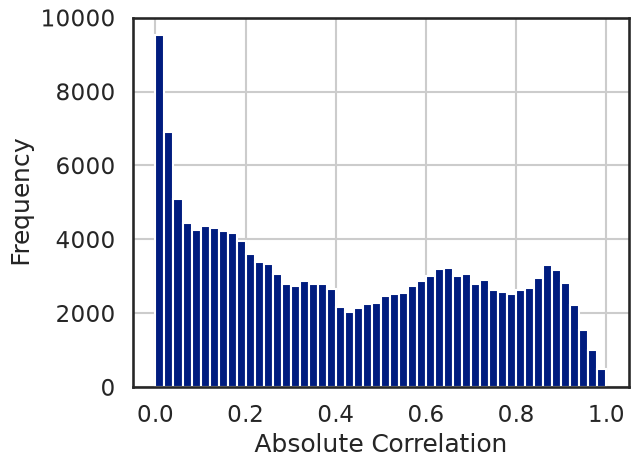

In [11]:
sns.set_context('talk')
sns.set_style('white')
sns.set_palette('dark')

ax = corr_values.abs_correlation.hist(bins=50)

ax.set(xlabel='Absolute Correlation', ylabel='Frequency');

In [12]:
# The most highly correlated values
high = corr_values.sort_values('correlation', ascending=False).query('abs_correlation>0.8')
print(f'пар с |r| > 0.8: {len(high)} ({len(high) / len(corr_values):.1%}), '
      f'с |r| > 0.99: {(corr_values.abs_correlation > 0.99).sum()}, '
      f'отрицательных среди |r| > 0.8: {(high.correlation < 0).sum()}')
high

пар с |r| > 0.8: 22815 (14.5%), с |r| > 0.99: 207, отрицательных среди |r| > 0.8: 2143


,feature1,feature2,correlation,abs_correlation
156894,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.000000,1.000000
156556,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.000000,1.000000
96706,tGravityAccMag-mean(),tGravityAccMag-sma(),1.000000,1.000000
96366,tBodyAccMag-arCoeff()4,tGravityAccMag-arCoeff()4,1.000000,1.000000
109498,tBodyGyroJerkMag-mean(),tBodyGyroJerkMag-sma(),1.000000,1.000000
...,...,...,...,...
22657,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425,0.993425
39225,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267,0.994267
38739,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628,0.994628
23176,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764,0.994764


**Ответ.**

Пар признаков 561·560/2 = 157 080. Гистограмма |r| двугорбая: много пар почти независимы (пик около 0), а второй горб на 0.6-0.9. Сильно связанных пар очень много: |r| > 0.8 у 22 815 пар (14.5%), |r| > 0.99 у 207. Среди пар с |r| > 0.8 отрицательных 2 143.

Сильнее всего коррелируют дубли - один и тот же сигнал, посчитанный по-разному:
- r = 1.000: `...Mag-mean()` и `...Mag-sma()`, например `fBodyBodyGyroJerkMag-mean()` и `fBodyBodyGyroJerkMag-sma()`. Для модуля сигнала (он неотрицательный) среднее и «signal magnitude area» по сути одна и та же величина;
- r около -0.995: `tGravityAcc-mean()-Z` и `angle(Z,gravityMean)`. Оба признака описывают, как телефон повернут относительно гравитации.

Вывод: признаки сильно мультиколлинеарны. Для логистической регрессии без штрафа это значит, что веса определены плохо: можно увеличить вес одного из почти одинаковых признаков и уменьшить вес другого, а прогноз почти не изменится. Отсюда огромные и неустойчивые коэффициенты в вопросе 5. Регуляризация выбирает из таких решений одно - с маленькими весами.

## Вопрос 3

* Разделите данные на обучающий и тестовый наборы. Это можно сделать любым способом, но рекомендуется использовать метод `StratifiedShuffleSplit` из библиотеки Scikit-learn, чтобы сохранить одинаковое соотношение классов предикторов.
* Независимо от метода, использованного для разделения данных, сравните соотношение классов в обучающем и тестовом наборах.


In [13]:
# Get the split indexes
strat_shuf_split = StratifiedShuffleSplit(n_splits=1,
                                          test_size=0.3,
                                          random_state=42)

train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.Activity))

# Create the dataframes
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test  = data.loc[test_idx, feature_cols]
y_test  = data.loc[test_idx, 'Activity']

In [14]:
y_train.value_counts(normalize=True)

Activity
0    0.188792
2    0.185046
1    0.172562
3    0.167152
5    0.149951
4    0.136496
Name: proportion, dtype: float64

In [15]:
y_test.value_counts(normalize=True)

Activity
0    0.188673
2    0.185113
1    0.172492
3    0.167314
5    0.149838
4    0.136570
Name: proportion, dtype: float64

In [16]:
pd.DataFrame({'train': y_train.value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)})\
  .rename(index=dict(enumerate(le.classes_))).round(4)

,train,test
Activity,,
LAYING,0.1888,0.1887
STANDING,0.1850,0.1851
SITTING,0.1726,0.1725
WALKING,0.1672,0.1673
WALKING_UPSTAIRS,0.1500,0.1498
WALKING_DOWNSTAIRS,0.1365,0.1366


**Ответ.**

`StratifiedShuffleSplit` (70/30, `random_state=42`) дал 7 209 записей в train и 3 090 в test. Доли классов совпадают до третьего знака (LAYING 0.1888 в train и 0.1887 в test и т. д.), стратификация сработала. При простом случайном разбиении расхождение тоже было бы небольшим (классы почти сбалансированы), но стратификация гарантирует, что метрики на test не зависят от случайного перекоса классов.

## Вопрос 4

* Постройте модель логистической регрессии без какой-либо регуляризации с использованием всех признаков. Обязательно ознакомьтесь с документацией по построению многоклассовых моделей, чтобы понять, как интерпретировать выведенные коэффициенты. Сохраните модель.
* Используя перекрестную валидацию для определения гиперпараметров, постройте модели с L1- и L2-регуляризацией. Сохраните также каждую из этих моделей. Обратите внимание на ограничения, связанные с многоклассовыми моделями, решателями и видами регуляризации. Построение регуляризованных моделей, в частности модели с L1-регуляризацией, вероятно, займет некоторое время.

In [17]:
# Standard logistic regression: без регуляризации. В исходной версии стояло C=.001 - это, наоборот, сильный
# L2-штраф. В sklearn 1.8+ параметр penalty устарел, отсутствие штрафа задается C=np.inf
t0 = time.time()
lr = LogisticRegression(C=np.inf, max_iter=1000).fit(X_train, y_train)
print(f'{time.time() - t0:.0f} с, итераций: {lr.n_iter_}')

32 с, итераций: [350]


In [18]:
# L1 regularized logistic regression.
# Решатель liblinear в sklearn 1.9 не принимает многоклассовую задачу напрямую, поэтому заворачиваю его
# в OneVsRestClassifier: 6 бинарных моделей "класс против остальных", у каждой C подбирается кросс-валидацией.
# (saga с L1 решает мультиномиальную задачу, но здесь не сходится и за 200 эпох.)
t0 = time.time()
lr_l1 = OneVsRestClassifier(
    LogisticRegressionCV(Cs=np.logspace(-2, 2, 9), cv=4, l1_ratios=(1,), solver='liblinear',
                         scoring='accuracy', use_legacy_attributes=False, n_jobs=4, random_state=42)
).fit(X_train, y_train)
print(f'{time.time() - t0:.0f} с')
print('выбранные C по классам:', {le.classes_[k]: round(float(est.C_), 3) for k, est in enumerate(lr_l1.estimators_)})

76 с
выбранные C по классам: {'LAYING': 1.0, 'SITTING': 10.0, 'STANDING': 3.162, 'WALKING': 100.0, 'WALKING_DOWNSTAIRS': 10.0, 'WALKING_UPSTAIRS': 31.623}


In [19]:
# L2 regularized logistic regression (в исходной версии Cs=1, то есть подбирать было не из чего)
t0 = time.time()
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=(0,), scoring='accuracy', use_legacy_attributes=False,
                             max_iter=1000, n_jobs=4).fit(X_train, y_train)
print(f'{time.time() - t0:.0f} с, выбранное C: {lr_l2.C_:.3f} из {np.round(lr_l2.Cs_, 4)}')

56 с, выбранное C: 2.783 из [1.0000000e-04 8.0000000e-04 6.0000000e-03 4.6400000e-02 3.5940000e-01
 2.7826000e+00 2.1544300e+01 1.6681010e+02 1.2915497e+03 1.0000000e+04]


**Ответ.**

**Без регуляризации (`lr`).** В исходном ноутбуке стояло `LogisticRegression(C=.001)`. Но C - это обратная сила регуляризации, и C = 0.001 значит очень **сильный** L2-штраф, а не его отсутствие. Без штрафа - это `C=np.inf` (в sklearn 1.8+ параметр `penalty` устарел). lbfgs сошелся за 350 итераций.

**Как устроены многоклассовые коэффициенты.** У lbfgs по умолчанию мультиномиальная (softmax) модель: для каждого из 6 классов свой вектор весов, `coef_` имеет размер 6 x 561, и P(k | x) = exp(w_k·x) / sum_j exp(w_j·x). Если ко всем w_k прибавить один и тот же вектор, вероятности не изменятся. Поэтому смысл имеют только **разности** весов между классами, а не сами веса. Без штрафа решение не единственное, а штраф выбирает решение с наименьшей нормой.

**L1 (`l1`).** Решатель `liblinear` (L1) в sklearn 1.9 не принимает многоклассовую задачу, а `saga` с L1 на этих данных, по моей отдельной проверке, не сходится и за 200 эпох (около 25 секунд на одно обучение). Поэтому `liblinear` завернут в `OneVsRestClassifier`: 6 отдельных бинарных моделей «класс против остальных». У каждой C подбирается своей 4-кратной кросс-валидацией из 9 значений от 0.01 до 100: LAYING 1, SITTING 10, STANDING 3.16, WALKING 100, WALKING_DOWNSTAIRS 10, WALKING_UPSTAIRS 31.6. Выбор неустойчив: точность на кросс-валидации для соседних C отличается на сотые доли процента, и без фиксированного `random_state` (у liblinear случайный порядок координат) при повторном запуске выбирались другие C. Здесь каждая строка `coef_` - отдельный бинарный классификатор, а вероятности нормируются уже после.

**L2 (`l2`).** `LogisticRegressionCV` с мультиномиальной моделью, 10 значений C от 1e-4 до 1e4 (в исходнике было `Cs=1`, то есть выбирать было не из чего), 4 фолда. Выбрано C = 2.78.

Все три модели обучились примерно за 3 минуты вместо 494 секунд, записанных в исходном ноутбуке.

## Вопрос 5

Сравните величины коэффициентов для каждой из моделей. Если использовалась подстановка «один против остальных», каждый набор коэффициентов можно отобразить на графике отдельно.

In [20]:
# Combine all the coefficients into a dataframe
coefficients = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]


def get_coef(mod):
    # у OneVsRestClassifier коэффициенты хранятся в каждой из 6 бинарных моделей
    if hasattr(mod, 'estimators_'):
        return np.vstack([est.coef_ for est in mod.estimators_])
    return mod.coef_


for lab,mod in zip(coeff_labels, coeff_models):
    coeffs = get_coef(mod)
    coeff_label = pd.MultiIndex(levels=[[lab], [0,1,2,3,4,5]],
                                codes=[[0,0,0,0,0,0], [0,1,2,3,4,5]])
    coefficients.append(pd.DataFrame(coeffs.T, columns=coeff_label))

coefficients = pd.concat(coefficients, axis=1)

coefficients.sample(10, random_state=42)

lr                                                          l1  \
             0          1          2          3          4          5    0   
513   3.410611  25.272590  10.714740 -35.784759 -12.962762   9.349580  0.0   
342   1.034487   2.995576   0.967703  -0.848355  -5.581428   1.432017  0.0   
177  -0.211798   1.529095   7.435710  -6.663898   3.843468  -5.932577  0.0   
86  -11.843931 -12.844875  -7.310889  13.460501   5.013916  13.525278  0.0   
333   0.766445   3.925291   6.801390  -5.313278   0.594974  -6.774823  0.0   
140  -7.312774   5.752809 -18.839241  15.857410  -6.394820  10.936615  0.0   
321  -1.680946   2.492122   0.917385  -3.662475   7.459177  -5.525263  0.0   
531  -2.350478  12.561471 -20.021112   9.969044   6.326120  -6.485046  0.0   
101  -5.499348   4.957168  -9.887161   8.277958   7.729917  -5.578534  0.0   
519  -5.347191  -7.934230   3.615207 -12.163789   9.561551  12.268452  0.0   

                                                             l2            \
            1         2         3         4         5         0         1   
513  0.000000 -0.503004 -2.200890  0.000000  1.298125  0.118839  0.391417   
342  0.000000  0.000000  0.020660  0.000000 -0.052861  0.013799  0.026612   
177  0.268648  0.000000 -0.134753  0.000000  0.092258 -0.066695 -0.012340   
86  -0.275744  0.000000 -0.015915  0.000000  0.000000 -0.085990 -0.170943   
333  0.361323  0.324967 -0.044556  0.123030  0.284020 -0.065710  0.022149   
140  0.000000  0.000000  1.052879  0.000000  1.139593 -0.070948  0.124213   
321  0.105892  0.000000  0.545582  0.118217 -0.025857 -0.060941  0.039510   
531  0.259142  0.000000  0.571580  0.222299 -0.341137  0.010221  0.404997   
101  0.000000  0.000000  0.275676  0.000000 -0.580963 -0.072455  0.144187   
519  0.000000  0.000000 -0.152848  0.000000  0.506013 -0.101193 -0.180911   

                                             
            2         3         4         5  
513 -0.007791 -0.748876 -0.168623  0.415034  
342  0.053106  0.020461 -0.079184 -0.034796  
177  0.116925 -0.079460  0.111273 -0.069704  
86  -0.067968  0.125503 -0.025205  0.224602  
333  0.082339 -0.028717  0.061154 -0.071215  
140 -0.310163  0.316741 -0.322715  0.262873  
321 -0.000306  0.068052  0.062852 -0.109167  
531 -0.507250  0.227905  0.027878 -0.163750  
101 -0.197753  0.189832  0.179764 -0.243575  
519  0.131289 -0.241899  0.078479  0.314235

Подготовьте шесть отдельных графиков для каждого из многоклассовых коэффициентов.

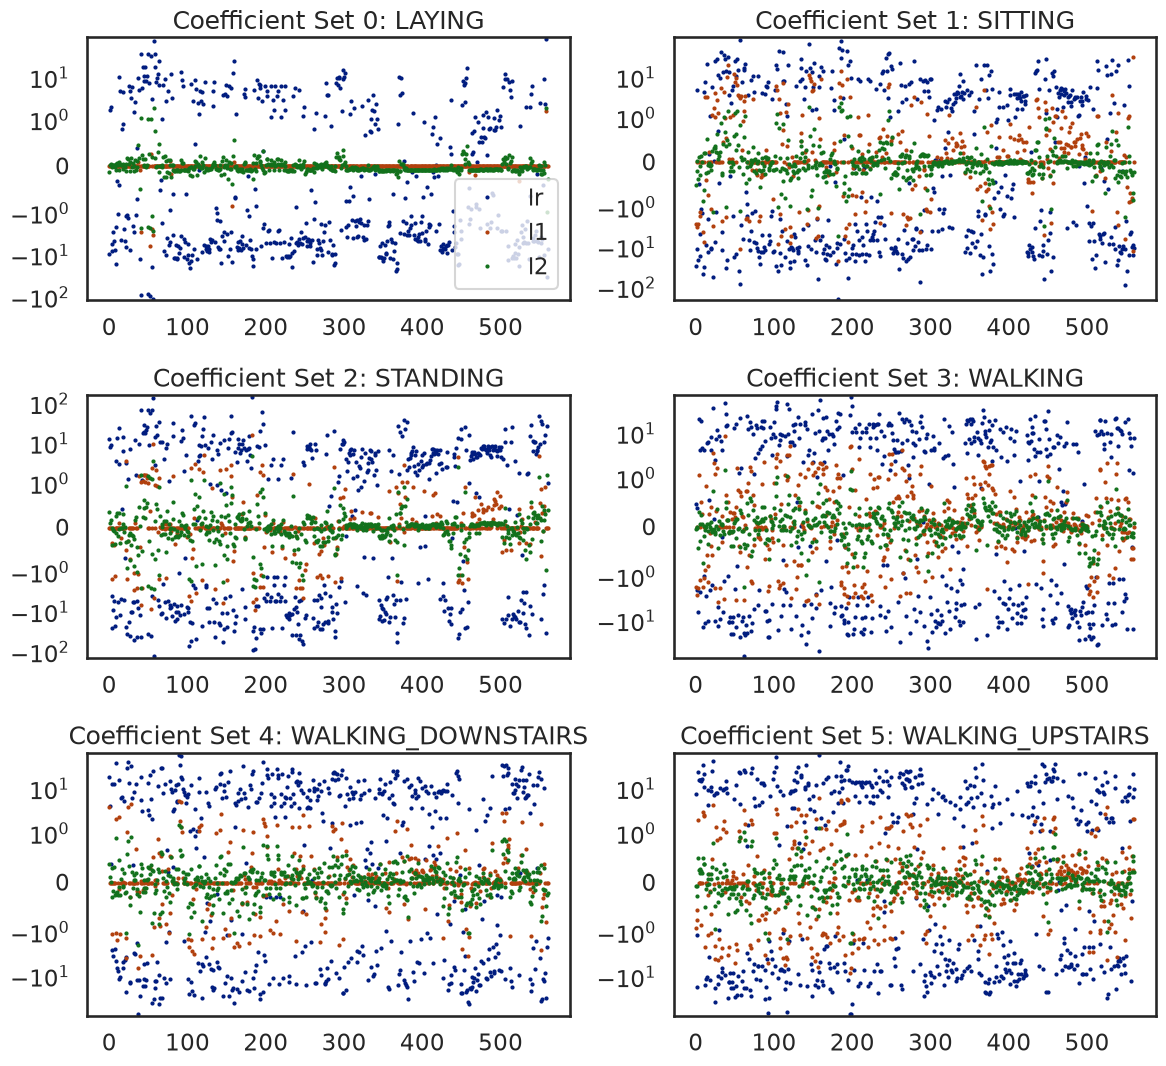

In [21]:
fig, axList = plt.subplots(nrows=3, ncols=2)
axList = axList.flatten()
fig.set_size_inches(12, 11)

for loc, ax in enumerate(axList):
    # в исходнике здесь затиралась переменная data
    coef_set = coefficients.xs(loc, level=1, axis=1)
    coef_set.plot(marker='o', ls='', ms=2.0, ax=ax, legend=False)
    ax.set_yscale('symlog', linthresh=1)   # иначе коэффициенты l1/l2 не видны рядом с lr

    if ax is axList[0]:
        ax.legend(loc=4)

    ax.set(title='Coefficient Set '+str(loc) + ': ' + le.classes_[loc])

plt.tight_layout()

In [22]:
# сводка по коэффициентам каждой модели
pd.DataFrame({lab: {'max |w|': np.abs(get_coef(mod)).max(),
                    'средний |w|': np.abs(get_coef(mod)).mean(),
                    'доля нулевых': (get_coef(mod) == 0).mean(),
                    'ненулевых признаков (хотя бы в одном классе)': int((get_coef(mod) != 0).any(axis=0).sum())}
              for lab, mod in zip(coeff_labels, coeff_models)}).round(4)

,lr,l1,l2
max |w|,195.3340,32.6268,5.2378
средний |w|,10.1557,0.5959,0.2260
доля нулевых,0.0000,0.4245,0.0000
ненулевых признаков (хотя бы в одном классе),561.0000,561.0000,561.0000


**Ответ.**

| | lr | l1 | l2 |
|---|---|---|---|
| max \|w\| | 195 | 33 | 5.2 |
| средний \|w\| | 10.2 | 0.60 | 0.23 |
| доля нулевых весов | 0 | 42% | 0 |

- **Без регуляризации веса огромные**: в среднем в 45 раз больше, чем у L2. На графиках (шкала symlog) синие точки разбросаны до ±100, зеленые (L2) лежат у нуля. Причины две: мультиколлинеарность из вопроса 2 и почти линейная разделимость классов. Если классы разделимы, логистическую функцию потерь всегда можно еще немного уменьшить, увеличив все веса, и без штрафа веса растут, пока решатель не остановится по точности.
- **L1 обнуляет 42% весов** (оранжевые точки лежат ровно на нуле), но ни один признак не выкинут из всех шести моделей сразу: каждый из 561 признаков нужен хоть какому-то классу. Разным классам нужны разные признаки.
- **L2 никого не обнуляет**, а равномерно уменьшает все веса.

Сравнивать `l1` с остальными напрямую можно только качественно: это шесть бинарных моделей one-vs-rest, а `lr` и `l2` - мультиномиальные.

## Вопрос 6

* Определите и сохраните класс для каждой модели.
* Также сохраните вероятность для предсказанного класса для каждой модели.

In [23]:
# Predict the class and the probability for each
y_pred = list()
y_prob = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab,mod in zip(coeff_labels, coeff_models):
    y_pred.append(pd.Series(mod.predict(X_test), name=lab))
    y_prob.append(pd.Series(mod.predict_proba(X_test).max(axis=1), name=lab))

y_pred = pd.concat(y_pred, axis=1)
y_prob = pd.concat(y_prob, axis=1)

y_pred.head()

,lr,l1,l2
0,3,3,3
1,5,5,5
2,3,3,3
3,1,1,1
4,0,0,0


In [24]:
y_prob.head()

,lr,l1,l2
0,1.0,0.999024,0.999998
1,1.0,0.999269,0.999708
2,1.0,0.998392,0.999059
3,1.0,0.999390,0.997659
4,1.0,0.999999,0.999315


In [25]:
# насколько модели уверены: доля прогнозов с вероятностью выше порога
pd.DataFrame({'средняя вероятность': y_prob.mean(), 'доля p > 0.99': (y_prob > 0.99).mean(),
              'доля p < 0.6': (y_prob < 0.6).mean(),
              'модели согласны между собой': [(y_pred.nunique(axis=1) == 1).mean()] * 3}).round(4)

,средняя вероятность,доля p > 0.99,доля p < 0.6,модели согласны между собой
lr,0.9992,0.9948,0.0006,0.9816
l1,0.9824,0.8375,0.0078,0.9816
l2,0.9799,0.7977,0.0078,0.9816


**Ответ.**

Все три модели дают один и тот же класс на 98.16% объектов test, но **уверенность у них разная**:
- `lr`: средняя вероятность выбранного класса 0.9992, и у 99.5% прогнозов p > 0.99. При этом модель ошибается на 1.8% объектов (55 из 3090, см. таблицу в вопросе 7), то есть она **переуверена**: если верить ее вероятностям, ошибок должно быть около 0.1%. Это следствие огромных весов: softmax от больших чисел почти всегда дает 0 или 1.
- `l2`: средняя вероятность 0.980, p > 0.99 только у 80% прогнозов. Ожидаемая по вероятностям доля ошибок около 2% близка к фактической (1.6%), вероятности почти откалиброваны.
- `l1`: посередине, средняя вероятность 0.982.

Регуляризация делает вероятности честнее. Это важно, если по ним принимаются решения (порог, ранжирование), а не только берется самый вероятный класс.

## Вопрос 7

Для каждой модели рассчитайте следующие показатели ошибок:

* точность
* прецизионность
* полнота
* F-показатель
* матрица путаницы

Определите, как объединить показатели для нескольких классов в одно значение для каждой модели.

In [26]:
metrics = list()
cm = dict()

for lab, mod in zip(coeff_labels, coeff_models):

    # Preciision, recall, f-score from the multi-class support function
    precision, recall, fscore, _ = score(y_test, y_pred[lab], average='weighted')

    # The usual way to calculate accuracy
    accuracy = accuracy_score(y_test, y_pred[lab])

    # ROC-AUC по вероятностям (каждый класс против остальных). В исходной версии AUC считался по жестким
    # меткам после label_binarize - это не ROC-кривая, а одна ее точка; оставляю его для сравнения
    auc = roc_auc_score(y_test, mod.predict_proba(X_test), multi_class='ovr', average='weighted')
    auc_hard = roc_auc_score(label_binarize(y_test, classes=[0,1,2,3,4,5]),
                             label_binarize(y_pred[lab], classes=[0,1,2,3,4,5]),
                             average='weighted')

    # Last, the confusion matrix
    cm[lab] = confusion_matrix(y_test, y_pred[lab])

    metrics.append(pd.Series({'precision':precision, 'recall':recall,
                              'fscore':fscore, 'accuracy':accuracy,
                              'auc':auc, 'auc по меткам':auc_hard,
                              'ошибок на test': int((y_pred[lab] != y_test.to_numpy()).sum())},
                             name=lab))

metrics = pd.concat(metrics, axis=1)

In [27]:
metrics

,lr,l1,l2
precision,0.982172,0.984147,0.983808
recall,0.982201,0.984142,0.983819
fscore,0.982179,0.984141,0.983812
accuracy,0.982201,0.984142,0.983819
auc,0.998762,0.999281,0.999465
auc по меткам,0.989212,0.990345,0.990170
ошибок на test,55.000000,49.000000,50.000000


In [28]:
print(classification_report(y_test, y_pred['l2'], target_names=le.classes_, digits=4))

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       583
           SITTING     0.9586    0.9550    0.9568       533
          STANDING     0.9599    0.9615    0.9607       572
           WALKING     0.9942    0.9981    0.9961       517
WALKING_DOWNSTAIRS     0.9976    0.9976    0.9976       422
  WALKING_UPSTAIRS     0.9978    0.9957    0.9968       463

          accuracy                         0.9838      3090
         macro avg     0.9847    0.9846    0.9847      3090
      weighted avg     0.9838    0.9838    0.9838      3090



**Ответ.**

| | lr | l1 | l2 |
|---|---|---|---|
| accuracy | 0.9822 | 0.9841 | 0.9838 |
| precision / recall / F1 (weighted) | 0.982 | 0.984 | 0.984 |
| ROC-AUC по вероятностям (OvR, weighted) | 0.9988 | 0.9993 | 0.9995 |
| ошибок на 3090 объектах | 55 | 49 | 50 |

Регуляризованные модели немного лучше по всем метрикам. По точности L1 и L2 разделяет одна ошибка, по AUC (качеству вероятностей) лучше всех L2.

**Как свести метрики классов в одно число.** precision, recall и F1 сначала считаются для каждого класса отдельно («класс против остальных»), а потом усредняются:
- `macro` - простое среднее, все классы равны;
- `weighted` - среднее с весами по числу объектов класса (использовано здесь);
- `micro` - TP, FP, FN суммируются по всем классам, а потом считается метрика. Для многоклассовой задачи с одной меткой micro-precision = micro-recall = accuracy.

Weighted recall всегда равен accuracy, это видно в таблице. Классы почти сбалансированы, поэтому macro и weighted почти совпадают (0.9847 и 0.9838 для F1 у `l2`).

**AUC.** В исходной версии AUC считался по жестким меткам после `label_binarize`. Это одна точка ROC-кривой, а не кривая, поэтому такой AUC занижен: 0.989-0.990. Правильно считать AUC по вероятностям `predict_proba`, тогда он 0.999.

По классам (`l2`): LAYING распознается идеально (F1 = 1.000), три вида ходьбы - с F1 0.996-0.998, а слабее всего SITTING (F1 0.957) и STANDING (0.961).

## Вопрос 8

Отобразите или постройте матрицу путаницы для каждой модели.

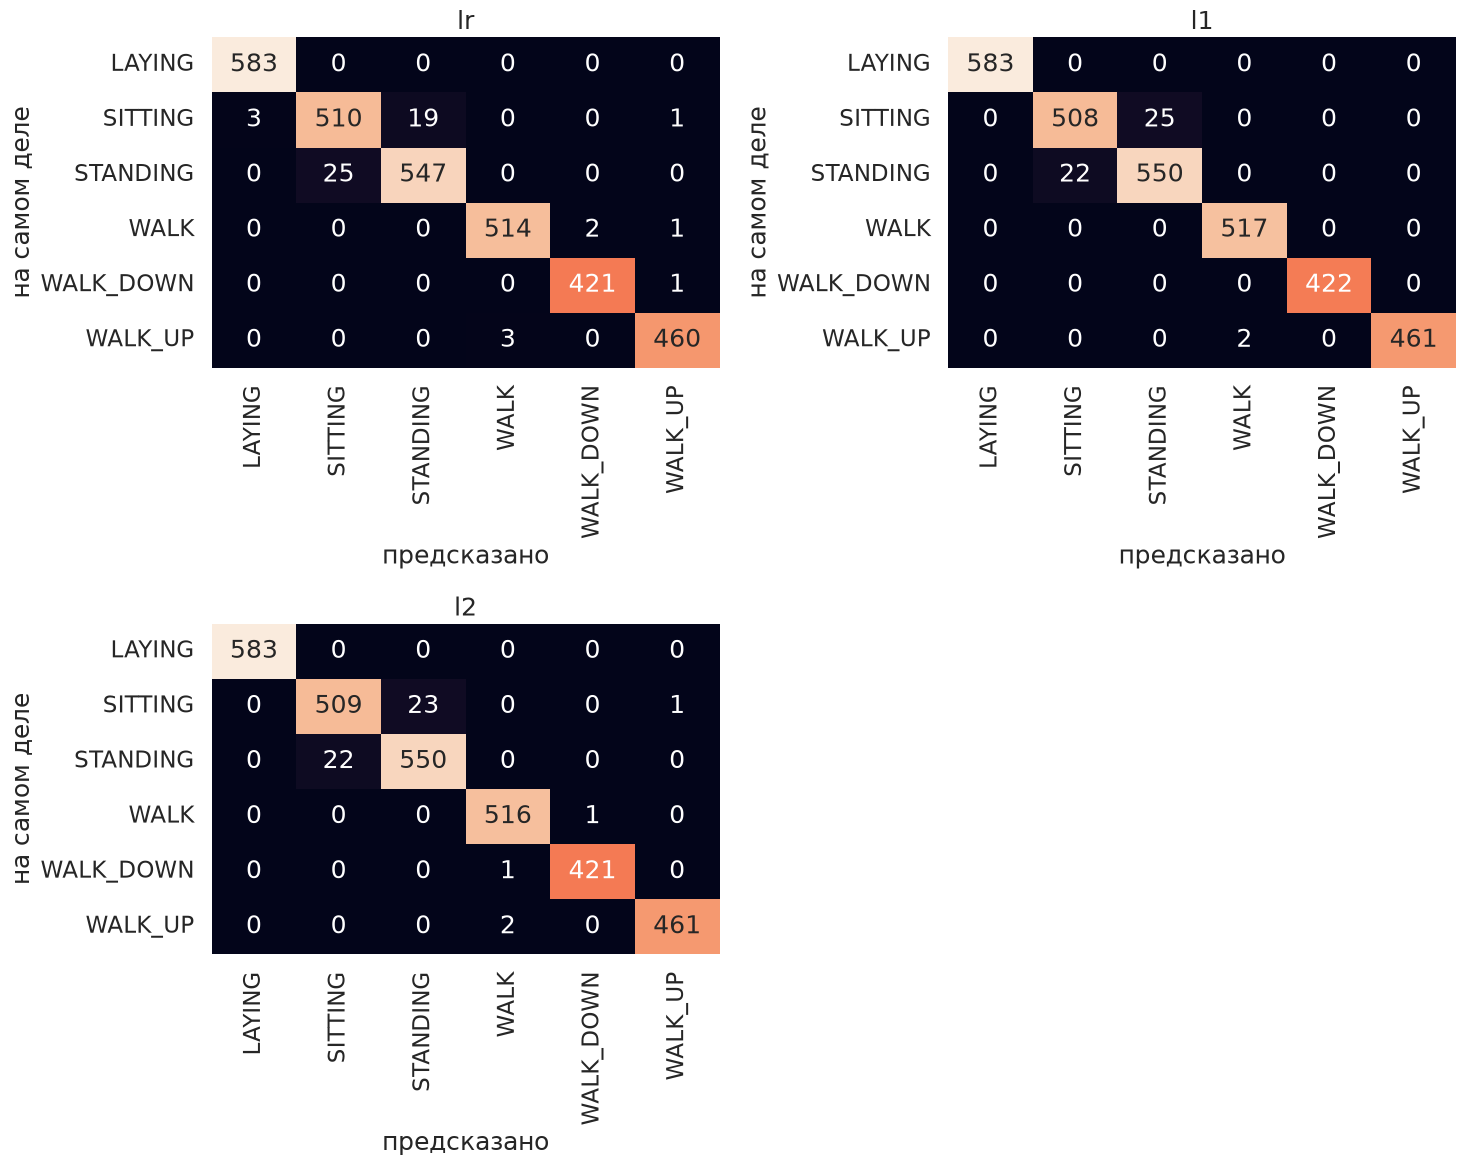

In [29]:
fig, axList = plt.subplots(nrows=2, ncols=2)
axList = axList.flatten()
fig.set_size_inches(15, 12)

axList[-1].axis('off')
short = ['LAYING', 'SITTING', 'STANDING', 'WALK', 'WALK_DOWN', 'WALK_UP']

for ax,lab in zip(axList[:-1], coeff_labels):
    sns.heatmap(cm[lab], ax=ax, annot=True, fmt='d', cbar=False,
                xticklabels=short, yticklabels=short);
    ax.set(title=lab, xlabel='предсказано', ylabel='на самом деле');

plt.tight_layout()

**Ответ.**

Во всех трех матрицах основная ошибка одна: **SITTING и STANDING путаются между собой**. Это 44 из 55 ошибок у `lr`, 47 из 49 у `l1` и 45 из 50 у `l2`. Обе позы статичные, телефон на поясе в обоих случаях почти неподвижен и одинаково повернут относительно гравитации, отличия в сигнале тонкие.

Остальное почти идеально:
- LAYING не путается ни с чем. Только `lr` трижды принял сидящего за лежащего: у лежащего человека гравитация направлена по другой оси телефона, это легко отличить;
- три вида ходьбы (обычная, вверх, вниз по лестнице) путаются между собой в 1-3 случаях из 1400: у движения яркий динамический след в сигнале.

Регуляризация убрала ошибки в основном **вне** пары сидеть/стоять: у `lr` таких ошибок 11, у `l1` 2, у `l2` 5. Саму пару SITTING/STANDING линейная модель на этих признаках лучше не разделяет. Тут нужны другие признаки или нелинейная модель.